# WCTE ring finder

Fit one event from PMT IDs, charges in PE, and hit times in ns.
Choose `"pion"`, `"proton"`, or `"muon"` for the incoming particle.
The simulation and ROOT examples use files included with this notebook.

The options below set the effective PMT floor for a counted ring and the largest fitted turn counted as one ring. The defaults are 30 PMTs and 15°. The timing and final count reviews use these settings. The two-cone seed fit requires 10 assigned PMTs per cone.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython import get_ipython
from IPython.display import display

from wcte.display import plot_event
from wcte.session import fit_event

get_ipython().run_line_magic("matplotlib", "inline")
example_dir = Path("examples") if Path("examples/data").is_dir() else Path(".")
data_dir = example_dir / "data"

# Use these track-counting thresholds for the simulation and data fits.
track_counting = dict(min_track_pmts=30.0, track_merge_angle_deg=15.0)

Matplotlib is building the font cache; this may take a moment.


In [2]:
def show_fit(fit, label):
    count = fit["ring_count"]
    print(f"{label} · {count} fitted ring(s) · {len(fit['pmt_ids'])} retained hits")
    if not len(fit["pmt_ids"]):
        return

    # Add measured and shared PE over all retained pulses on each PMT.
    pmts, rows = np.unique(fit["pmt_ids"], return_inverse=True)
    charge = np.bincount(rows, weights=fit["charges"])
    shares = np.zeros((len(pmts), count + 1))
    np.add.at(shares, rows, fit["shared_charge_pe"])

    fig, _ = plot_event(pmts, charge, title=f"{label} · Prompt charge")
    display(fig)
    plt.close(fig)
    fig, _ = plot_event(pmts, shares.argmax(axis=1), ring_count=count,
                        title=f"{label} · Ring finder prediction")
    display(fig)
    plt.close(fig)

## Simulation · WCSim NPZ

The included single-event export contains the three digit arrays for
event 0 of the 300 MeV pion sample. Use the zero-based WCSim tube IDs
as stored. The fit uses the nominal `[-8, +7)` ns gate around the
detected prompt peak.

WCSim event 0 · 2 fitted ring(s) · 500 retained hits


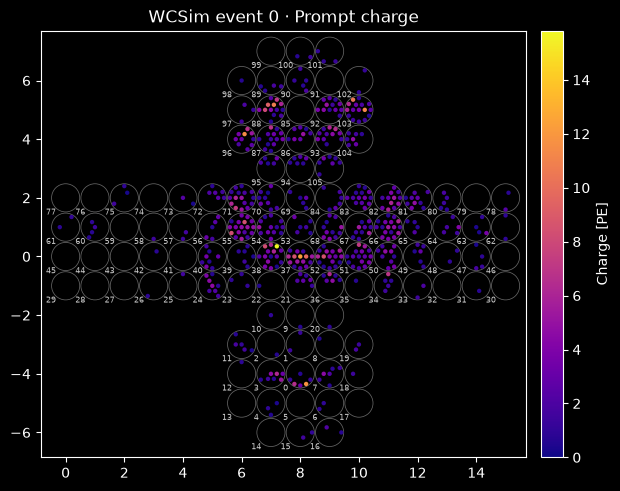

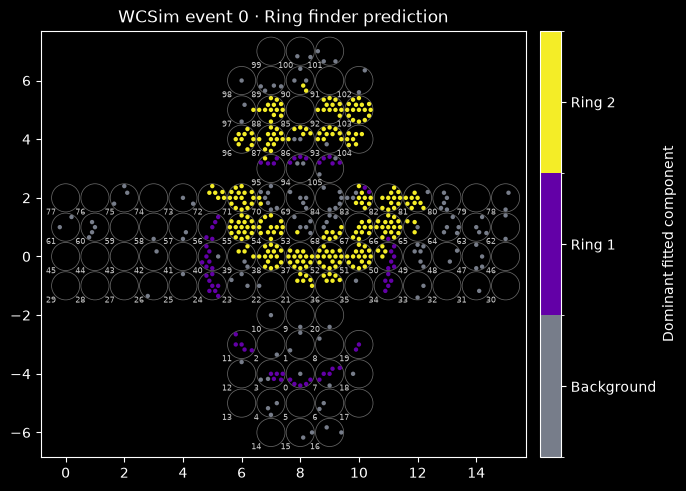

In [3]:
sim_file = data_dir / "wcsim_pion_300mev_event0.npz"
sim_event_id = 0
sim_particle = "pion"

with np.load(sim_file, allow_pickle=False) as digits:
    sim_ids, sim_pe, sim_ns = (digits[key] for key in ("raw_pmt_ids", "charges", "times"))

sim_fit = fit_event(sim_ids, sim_pe, sim_ns, event_id=sim_event_id,
                    incoming_particle=sim_particle, pmt_id_space="wcsim",
                    **track_counting)
show_fit(sim_fit, f"WCSim event {sim_event_id}")

## Real data · preselected ROOT entry

The local ROOT excerpt contains one row at index 0. It preserves
the digit branches and event number of Run 2079 entry 15. The
example reads just that row, applies the hit mask and upstream
input window, and converts calibrated ADC to PE. Choose your event
and any T5 or other trigger cuts before passing its hits to the fitter.

Set `input_window_ns = None` to pass the full readout after the hit
mask. Keep `fit_window_ns = None` for the nominal prompt gate or
supply the final fit interval in the same clock as the hits. Both
intervals include the lower endpoint and exclude the upper one.

In [4]:
import awkward as ak
import uproot

root_file = data_dir / "wcte_run2079_entry15.root"
root_entry = 0
data_particle = "pion"
adc_per_pe = 143.0
input_window_ns = (1972.915, 2372.915)
fit_window_ns = None
run_survey = data_dir / "run2079_geometry.npz"
clock_decimals = 3  # Run 2079 relative time precision is 1 ps.
apply_hit_dq = True

hit_fields = (
    "hit_mpmt_slot_ids", "hit_pmt_position_ids",
    "hit_pmt_charges", "hit_pmt_calibrated_times",
)
branches = ["event_number", *hit_fields]
if apply_hit_dq:
    branches.append("hit_pmt_readout_mask")
with uproot.open(root_file) as root:
    tree = root["WCTEReadoutWindows"]
    if not 0 <= root_entry < tree.num_entries:
        raise IndexError(f"ROOT entry {root_entry} is outside this tree")
    event = tree.arrays(branches, entry_start=root_entry,
                        entry_stop=root_entry + 1, library="ak")[0]

slot, position = (ak.to_numpy(event[field]).astype(np.int64) for field in hit_fields[:2])
adc, times = (ak.to_numpy(event[field]).astype(float) for field in hit_fields[2:])
keep = (slot >= 0) & (position >= 0) & (position < 19)
if apply_hit_dq:
    keep &= ak.to_numpy(event["hit_pmt_readout_mask"]) == 0
if input_window_ns is not None:
    low, high = input_window_ns
    keep &= (times >= low) & (times < high)
pmt_ids = 100 * slot[keep] + position[keep]
charges_pe = adc[keep] / adc_per_pe
hit_times_ns = times[keep]
event_number = int(event["event_number"])

Run 2079 · event 15 · 3 fitted ring(s) · 278 retained hits


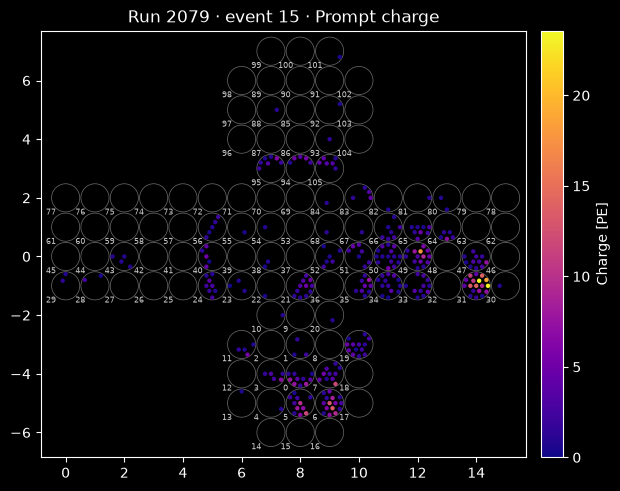

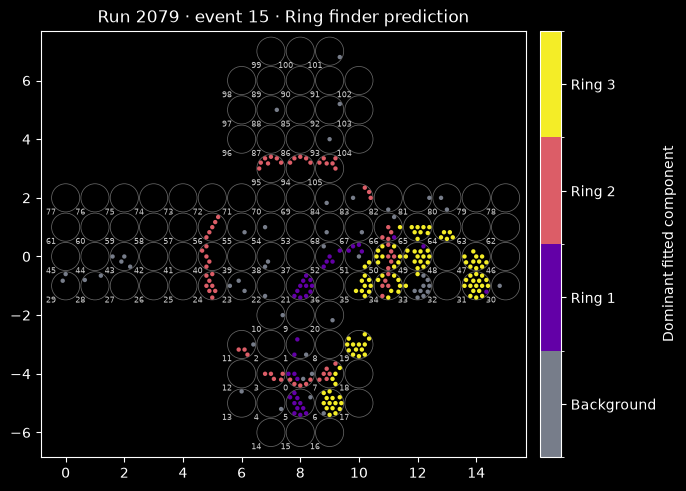

In [5]:
# Start here if your analysis already has the three selected hit arrays.
data_fit = fit_event(
    pmt_ids, charges_pe, hit_times_ns, incoming_particle=data_particle,
    event_id=event_number, survey=run_survey, pmt_id_space="wcte",
    prompt_window_ns=fit_window_ns, clock_decimals=clock_decimals,
    **track_counting,
)
show_fit(data_fit, f"Run 2079 · event {event_number}")

Both plots use the fitter's retained pulses. The prediction shows
the component with the largest shared PE at each PMT. Use
`sim_fit["shared_charge_pe"]` or `data_fit["shared_charge_pe"]` for all
components. Column zero is background. The other columns follow
the fitted ring order. `input_indices` indexes the input arrays.